In [22]:
package CoolSpineSystemContext {

    // Load after CoolSpineRequirements + CoolSpineSystem (name-sorted order).
    private import ScalarValues::*;
    private import CoolSpineSystem::*;

    // ------------------------------------------------------------------
    // People in the OR
    // ------------------------------------------------------------------

    part def Patient {
        doc /*
        Person receiving cooling. The CoolSpine catheter is the heat-exchange
        path in the patient. A separate CSF drain may be used for pressure /
        drainage monitoring (not part of the CoolSpine fluid loop).
        */
    }

    part def Surgeon {
        doc /*
        Lead clinician for the procedure. Decides whether to use CoolSpine and
        may ask for changes to cooling or flow; does not usually drive the
        device UI (that is the anesthesiologist).
        */
    }

    part def Anesthesiologist {
        doc /*
        Clinician who watches patient physiology and is the main operator of
        CoolSpine (power on, setpoints, stop) during the case.
        */
    }

    // ------------------------------------------------------------------
    // Optional CSF drain (hospital equipment next to CoolSpine)
    // ------------------------------------------------------------------

    part def PressureSensor {
        doc /*
        Measures CSF pressure at the stopcock. Reading can go to an optional
        bedside display. (Different from CoolSpine's saline pressure sensors.)
        */
    }

    part def Display {
        doc /* Optional screen showing CSF pressure from the drain set. */
    }

    part def Stopcock {
        doc /*
        Valve that controls CSF into the burette and is where the pressure
        sensor taps the line.
        */
    }

    part def Burette {
        doc /*
        Clear chamber that receives CSF from the stopcock before it drains
        into the collection bag; used with the scale to read level/pressure.
        */
    }

    part def CollectionBag {
        doc /* Bag that collects CSF from the burette. */
    }

    part def GraduatedScale {
        doc /*
        Ruler / scale next to the burette so staff can read fluid level and
        related pressure values.
        */
    }

    part def LevelingDevice {
        doc /*
        Helps align the scale to a clinical zero height (often near the ear
        canal) so pressure readings are meaningful.
        */
    }

    part def CsfDrain {
        doc /*
        Standard external CSF drain set used beside CoolSpine when ICP /
        drainage monitoring is needed. Fluid path: stopcock → burette → bag,
        with pressure sense, optional display, scale, and leveling.
        Not the CoolSpine saline loop.
        */

        part pressureSensor : PressureSensor;
        part display : Display [0..1];
        part stopcock : Stopcock;
        part burette : Burette;
        part collectionBag : CollectionBag;
        part graduatedScale : GraduatedScale;
        part levelingDevice : LevelingDevice;

        connection csfIntoBurette
            connect stopcock to burette {
            doc /* CSF flows from stopcock into the burette. */
        }
        connection csfToCollectionBag
            connect burette to collectionBag {
            doc /* CSF drains from burette into the bag. */
        }

        connection senseCsfPressure
            connect stopcock to pressureSensor {
            doc /* Pressure is sensed at the stopcock. */
        }

        connection displayCsfPressure
            connect pressureSensor to display {
            doc /* Pressure value shown on the optional display. */
        }

        connection indicateFluidLevel
            connect graduatedScale to burette {
            doc /* Scale is read against the burette fluid level. */
        }

        connection alignScaleLevel
            connect levelingDevice to graduatedScale {
            doc /* Leveling sets the scale to the clinical reference height. */
        }
    }

    // ------------------------------------------------------------------
    // Operating room picture (who is there with the device)
    // ------------------------------------------------------------------

    part def Context {
        doc /*
        One operating-room snapshot: CoolSpine device, patient, surgeon,
        anesthesiologist, and optionally a CSF drain.

        CoolSpine's saline stays inside the device loop
        (reservoir → catheter → pump → reservoir). The catheter is the only
        part of that loop inside the patient. The CSF drain is separate
        hospital gear for monitoring, not CoolSpine plumbing.
        */

        part coolSpine : CoolSpineDevice;
        part patient : Patient;
        part surgeon : Surgeon;
        part anesthesiologist : Anesthesiologist;
        part csfDrain : CsfDrain [0..1];

        connection drainPatientCsf
            connect patient to csfDrain {
            doc /* Patient CSF line into the optional drain set. */
        }
    }

    // ------------------------------------------------------------------
    // Who does what during a cooling case (simple sequence)
    // ------------------------------------------------------------------

    part def ClinicalCoolingInteraction {
        doc /*
        Step-by-step clinical flow while CoolSpine is used: surgeon asks for
        cooling, anesthesiologist configures the device, CoolSpine delivers
        therapy, setpoints may change mid-case, then everyone shuts down.
        Same people and device as in the OR context — this is the workflow,
        not a second copy of the hardware.
        */

        ref part surgeon : Surgeon {
            perform operateTherapy.requestCooling;
            perform operateTherapy.requestChange;
            perform operateTherapy.endProcedure;
        }

        ref part anesthesiologist : Anesthesiologist {
            perform operateTherapy.setSetpoints;
            perform operateTherapy.adjustSetpoints;
            perform operateTherapy.stopTherapy;
        }

        ref part coolSpine : CoolSpineDevice {
            perform operateTherapy.deliverTherapy;
            perform operateTherapy.applyAdjustment;
            perform operateTherapy.shutdown;
        }

        perform action operateTherapy {
            doc /*
            Typical order of work:
            1) surgeon requests cooling
            2) anesthesiologist sets flow / temperature
            3) CoolSpine runs
            4) surgeon may ask for a change → anesthesiologist updates → device applies
            5) case ends → stop → device standby
            */

            action requestCooling {
                doc /* Surgeon asks for therapeutic cooling for this patient. */
            }

            action setSetpoints {
                doc /* Anesthesiologist enters initial flow and temperature. */
            }

            action deliverTherapy {
                doc /* CoolSpine runs the saline loop and cools. */
            }

            action requestChange {
                doc /* Surgeon asks for a different setpoint during the case. */
            }

            action adjustSetpoints {
                doc /* Anesthesiologist changes flow / temperature on the UI. */
            }

            action applyAdjustment {
                doc /* CoolSpine applies the new setpoints. */
            }

            action endProcedure {
                doc /* Surgeon says cooling is no longer needed. */
            }

            action stopTherapy {
                doc /* Anesthesiologist stops therapy on the device. */
            }

            action shutdown {
                doc /* CoolSpine stops the loop and goes to standby. */
            }

            first start;
            then requestCooling;
            then setSetpoints;
            then deliverTherapy;
            then requestChange;
            then adjustSetpoints;
            then applyAdjustment;
            then endProcedure;
            then stopTherapy;
            then shutdown;
            then done;
        }
    }
}


Package CoolSpineSystemContext (c2d7d057-dc35-4699-bbec-6a1a4aeaf5c2)


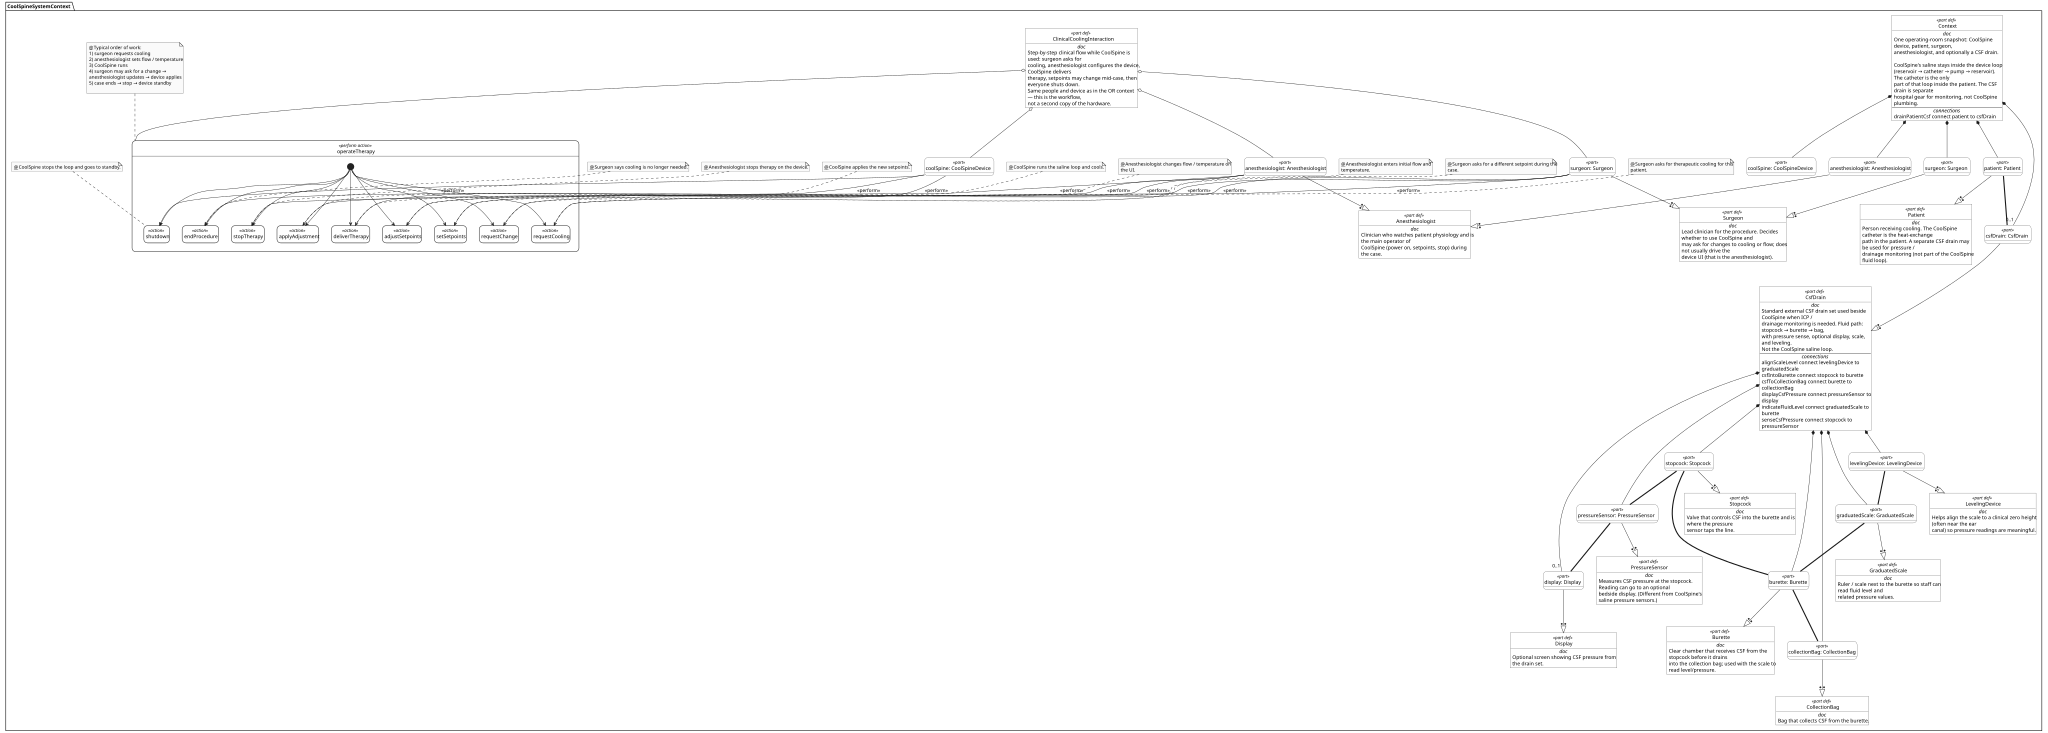

In [23]:
%viz CoolSpineSystemContext

In [3]:
package CoolSpineRequirements {

    // Source numbers: Spec/functional_requirements.csv
    private import ScalarValues::*;

    requirement def CoolSpineRequirement;

    requirement <'SYS-CS-001'> CoolSpineSystemRequirements : CoolSpineRequirement {
        doc /*
        Top-level need: CoolSpine must meet the cooling power, battery /
        portability, fluid pressure, user interface, and safety rules listed
        below. Use this as the checklist for the whole product.
        */
    }

    // --- Cooling performance ---

    requirement <'REQ-CP-001'> PeakCoolingPower : CoolSpineRequirement {
        doc /*
        Must be able to remove heat at 250 W peak (never less; up to +500 W
        is acceptable). Comes from sponsor animal studies / modeling — drives
        sizing of the micro-refrigeration unit.
        */
        attribute peakCoolingPower_W : Real default 250.0;
    }

    requirement <'REQ-CP-002'> SteadyStateCoolingPower : CoolSpineRequirement {
        doc /*
        Must sustain 150 W of cooling in steady state (never less; up to
        +300 W acceptable). Same study basis as peak power; this is the
        continuous duty the fridge and loop must hold.
        */
        attribute steadyStateCoolingPower_W : Real default 150.0;
    }

    // --- Power and portability ---

    requirement <'REQ-CP-003'> OperationWithoutGroundPower : CoolSpineRequirement {
        doc /*
        Must run at least 30 minutes without wall power (never less; up to
        +60 min acceptable) — e.g. moving the patient or brief AC loss.
        Battery + UPS design; aligned with clinical practice / IEC 60601-2-24.
        */
        attribute batteryRuntime_min : Real default 30.0;
    }

    requirement <'REQ-CP-004'> PortableFormFactor : CoolSpineRequirement {
        doc /*
        Device must be small / wheeled enough to move with the patient between
        rooms. Influences packaging, weight, and cable layout — not just the
        fridge performance.
        */
    }

    // --- Fluid pressure ---

    requirement <'REQ-CP-005'> OperatingPressure : CoolSpineRequirement {
        doc /*
        Normal saline-loop pressure: 15 PSI (−2 / +10 PSI). Sized for the
        catheter design; pump and sensors must stay in this band in use.
        */
        attribute operatingPressure_psi : Real default 15.0;
    }

    requirement <'REQ-CP-006'> MaximumPressure : CoolSpineRequirement {
        doc /*
        Hard ceiling: fluid circuit must not exceed 1.2 KSI. Protects catheter
        and patient; software and hardware limits should enforce this.
        */
        attribute maximumPressure_ksi : Real default 1.2;
    }

    // --- Usability and safety ---

    requirement <'REQ-CP-007'> AppropriateUserInterface : CoolSpineRequirement {
        doc /*
        Touch UI and controls must be usable and compliant for a medical
        electrical device (IEC 60601-1). Think alarms, labels, and operable
        by the anesthesiologist under OR conditions.
        */
    }

    requirement <'REQ-CP-008'> SafetyMonitoringAndFailSafes : CoolSpineRequirement {
        doc /*
        Must monitor for unsafe conditions and fail safe (alarms / shutdown)
        per IEC 60601-1-8 and IEC 60601-1-10. Covers sensor faults, pressure
        trips, and loss of control — not only the happy path.
        */
    }
}


Package CoolSpineRequirements (1145416b-65c5-4a5a-aa00-881cd926bbef)


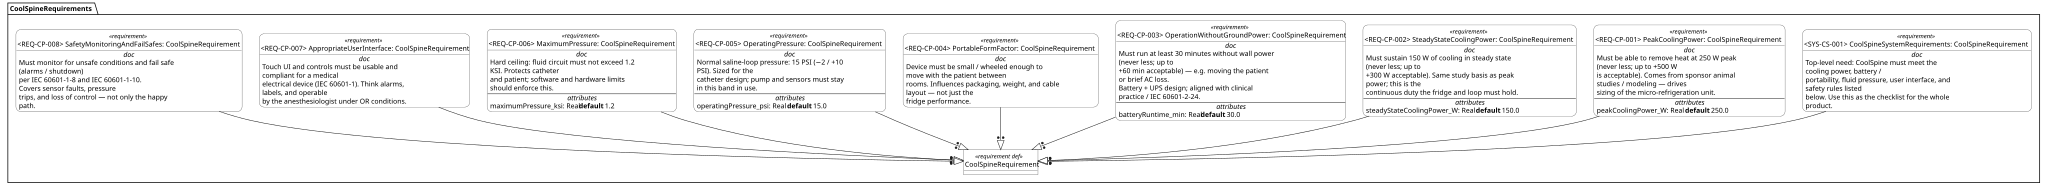

In [21]:
%viz CoolSpineRequirements

In [8]:
package CoolSpineSystem {

    private import ScalarValues::*;
    private import CoolSpineRequirements::*;

    // ------------------------------------------------------------------
    // Device hardware (clinical people / OR setup: CoolSpineSystemContext)
    // ------------------------------------------------------------------

    part def UPS {
        doc /*
        Wall-power box for the device. Takes AC from the room, outputs DC
        for the controller, and can keep running from the battery if wall
        power is lost.
        */
    }

    part def Battery {
        doc /*
        Backup battery so CoolSpine can keep running when unplugged or
        during transport (target: at least 30 minutes).
        */

        satisfy 'REQ-CP-003';  // OperationWithoutGroundPower
    }

    part def Compressor {
        doc /*
        Small compressor in the cooling module. Pushes refrigerant through
        the cold plate so heat can be pulled out of the saline.
        */
    }

    part def CoolPlate {
        doc /*
        Metal cold plate where saline is chilled. Heat moves from the saline
        into the refrigerant loop on the other side of the plate.
        */
    }

    part def CustomMicroRefrigerationUnit {
        doc /*
        On-board fridge for the saline. The controller turns it on/off.
        Inside: compressor + cold plate, plus two temperature probes on the
        heat exchanger so software can watch cooling performance.
        */

        satisfy 'REQ-CP-001';  // PeakCoolingPower
        satisfy 'REQ-CP-002';  // SteadyStateCoolingPower

        part compressor : Compressor;
        part coolPlate : CoolPlate;
        part heatExchange1 : Thermocouple;
        part heatExchange2 : Thermocouple;

        connection refrigerantLoop
            connect compressor to coolPlate {
            doc /* Refrigerant circulates between compressor and cold plate. */
        }
        connection senseHeatExchange1
            connect coolPlate to heatExchange1 {
            doc /* Temperature probe 1 on the cold-plate heat exchanger. */
        }
        connection senseHeatExchange2
            connect coolPlate to heatExchange2 {
            doc /* Temperature probe 2 on the cold-plate heat exchanger. */
        }
    }

    part def FluidReservoir {
        doc /*
        Saline tanks on the device: cold saline goes out to the patient
        catheter; warmer saline comes back from the pump. Two thermistors
        measure saline temperature on the way in and out.
        */

        satisfy 'REQ-CP-005';  // OperatingPressure
        satisfy 'REQ-CP-006';  // MaximumPressure

        part inputTempSensor : Thermistor;
        part outputTempSensor : Thermistor;
    }

    part def Catheter {
        doc /*
        Tube placed in the patient. Cold saline flows in, takes up heat from
        tissue / CSF, and returns warmer toward the pump. Tip sensor measures
        CSF temperature for the controller.
        */

        part csfTempSensor : Thermistor;
    }

    part def PeristalticPump {
        doc /*
        Pump that moves saline around the closed loop (catheter → reservoir).
        Speed/flow is set by the controller. Pressure sensors sit before and
        after the pump head for safety monitoring.
        */

        satisfy 'REQ-CP-005';  // OperatingPressure
        satisfy 'REQ-CP-006';  // MaximumPressure

        part inputPressureSensor : PressureSensor;
        part outputPressureSensor : PressureSensor;

        connection salineThroughPump
            connect inputPressureSensor to outputPressureSensor {
            doc /* Saline path through the pump (inlet → outlet). */
        }
    }

    part def PressureSensor {
        doc /*
        Fluid pressure sensor in the saline circuit (used at the pump inlet
        and outlet). Controller reads it for operating / max pressure limits.
        */

        satisfy 'REQ-CP-005';  // OperatingPressure
        satisfy 'REQ-CP-006';  // MaximumPressure
    }

    abstract part def TemperatureSensor {
        doc /*
        Any temperature probe the controller can read. Two kinds are used
        in this design: thermistor (more accurate, saline/CSF) and
        thermocouple (cooling module heat exchanger).
        */

        attribute accuracy : Real;  // measurement accuracy, ± °C
    }

    part def Thermistor :> TemperatureSensor {
        doc /*
        Cheap, accurate temperature sensor (±0.1 °C). Resistance changes with
        temperature; the Pi reads it through the analog ADC. Used for saline
        and CSF temperatures.
        */

        attribute :>> accuracy = 0.1;  // ± 0.1 °C
    }

    part def Thermocouple :> TemperatureSensor {
        doc /*
        Temperature sensor for the refrigeration heat exchanger (±1 °C).
        Needs a thermocouple input board (see Spec/Thermocouples DAQ …/).
        */

        attribute :>> accuracy = 1.0;  // ± 1 °C
    }

    // ------------------------------------------------------------------
    // Controller stack (Pi + power + ADC + screen)
    // ------------------------------------------------------------------

    part def RaspberryPi {
        doc /*
        Computer that runs CoolSpine control software (setpoints, sensing,
        safety). Hardware details: Spec/Pi & Screen/.
        */
    }

    part def PowerHat {
        doc /*
        Board that takes DC from the UPS and cleanly powers the Raspberry Pi.
        */
    }

    part def AdafruitAnalogInput {
        doc /*
        Multi-channel ADC (ADS1115 or equivalent) that digitizes temperature
        and pressure analog signals for the Pi. See Spec/ads1115/.
        */
    }

    part def TouchDisplay {
        doc /*
        Touch screen for the clinician: start/stop, setpoints, status and
        alarms. Driven by the Pi.
        */

        satisfy 'REQ-CP-007';  // AppropriateUserInterface
    }

    part def Controller {
        doc /*
        Brain of the device: Raspberry Pi + power board + ADC + touch screen.
        Powered from the UPS. Reads all sensors, shows the UI, sets pump flow,
        and switches the refrigeration module on/off.
        */

        part raspberryPi : RaspberryPi;
        part powerHat : PowerHat;
        part adc : AdafruitAnalogInput;
        part touchDisplay : TouchDisplay;

        connection supplyPiPower
            connect powerHat to raspberryPi {
            doc /* DC power from the power board to the Pi. */
        }

        connection adcInterface
            connect raspberryPi to adc {
            doc /* Digital bus (I2C) from Pi to the ADC chip. */
        }

        connection operatorInterface
            connect raspberryPi to touchDisplay {
            doc /* Screen and touch input between Pi and display. */
        }
    }

    // ------------------------------------------------------------------
    // Whole CoolSpine device
    // ------------------------------------------------------------------

    part def CoolSpineDevice {
        doc /*
        CoolSpine — portable device that cools a patient during spinal /
        neurosurgery by circulating cold saline through a catheter.

        How the fluid moves (closed loop):
          cold reservoir → catheter (in the patient) → pump → reservoir

        What the controller does: powered from UPS (+ battery backup), reads
        pressures and temperatures, shows the touch UI, sets pump flow, and
        turns the mini-fridge (micro-ref) on/off.

        People and the OR setup are modeled separately (operating context);
        this block is only the machine.
        */

        satisfy 'REQ-CP-004';  // PortableFormFactor
        satisfy 'REQ-CP-008';  // SafetyMonitoringAndFailSafes

        part ups : UPS;
        part battery : Battery;
        part controller : Controller;
        part microRef : CustomMicroRefrigerationUnit;
        part reservoir : FluidReservoir;
        part catheter : Catheter;
        part pump : PeristalticPump;

        // Power
        connection supplyBackupPower
            connect battery to ups {
            doc /* Battery feeds the UPS when wall power is gone. */
        }
        connection supplyControllerPower
            connect ups to controller {
            doc /* UPS provides DC power to the controller. */
        }

        // Commands
        connection setFlowRate
            connect controller to pump {
            doc /* Software commands how fast the pump runs. */
        }
        connection enableRefrigeration
            connect controller to microRef {
            doc /* Software turns the cooling module on or off. */
        }

        // Sensing (sensors sit on the parts they measure)
        connection sensePumpInletPressure
            connect pump.inputPressureSensor to controller {
            doc /* Pump inlet pressure → controller. */
        }
        connection sensePumpOutletPressure
            connect pump.outputPressureSensor to controller {
            doc /* Pump outlet pressure → controller. */
        }
        connection senseReservoirInputTemp
            connect reservoir.inputTempSensor to controller {
            doc /* Warmer return saline temperature into the reservoir. */
        }
        connection senseReservoirOutputTemp
            connect reservoir.outputTempSensor to controller {
            doc /* Cold saline temperature leaving the reservoir. */
        }
        connection senseCsfTemp
            connect catheter.csfTempSensor to controller {
            doc /* CSF temperature at the catheter tip → controller. */
        }
        connection senseHeatExchange1Temp
            connect microRef.heatExchange1 to controller {
            doc /* Cooling-module temperature probe 1 → controller. */
        }
        connection senseHeatExchange2Temp
            connect microRef.heatExchange2 to controller {
            doc /* Cooling-module temperature probe 2 → controller. */
        }

        // Closed saline loop
        connection coldSalineSupply
            connect reservoir to catheter {
            doc /* Cold saline out to the patient catheter. */
        }
        connection warmSalineReturn
            connect catheter to pump {
            doc /* Warmer saline from the catheter into the pump. */
        }
        connection warmSalineToReservoir
            connect pump to reservoir {
            doc /* Pump returns saline to the reservoir. */
        }
    }
}


Package CoolSpineSystem (a806ff5c-0290-4d18-a20c-e13d22fd3e26)


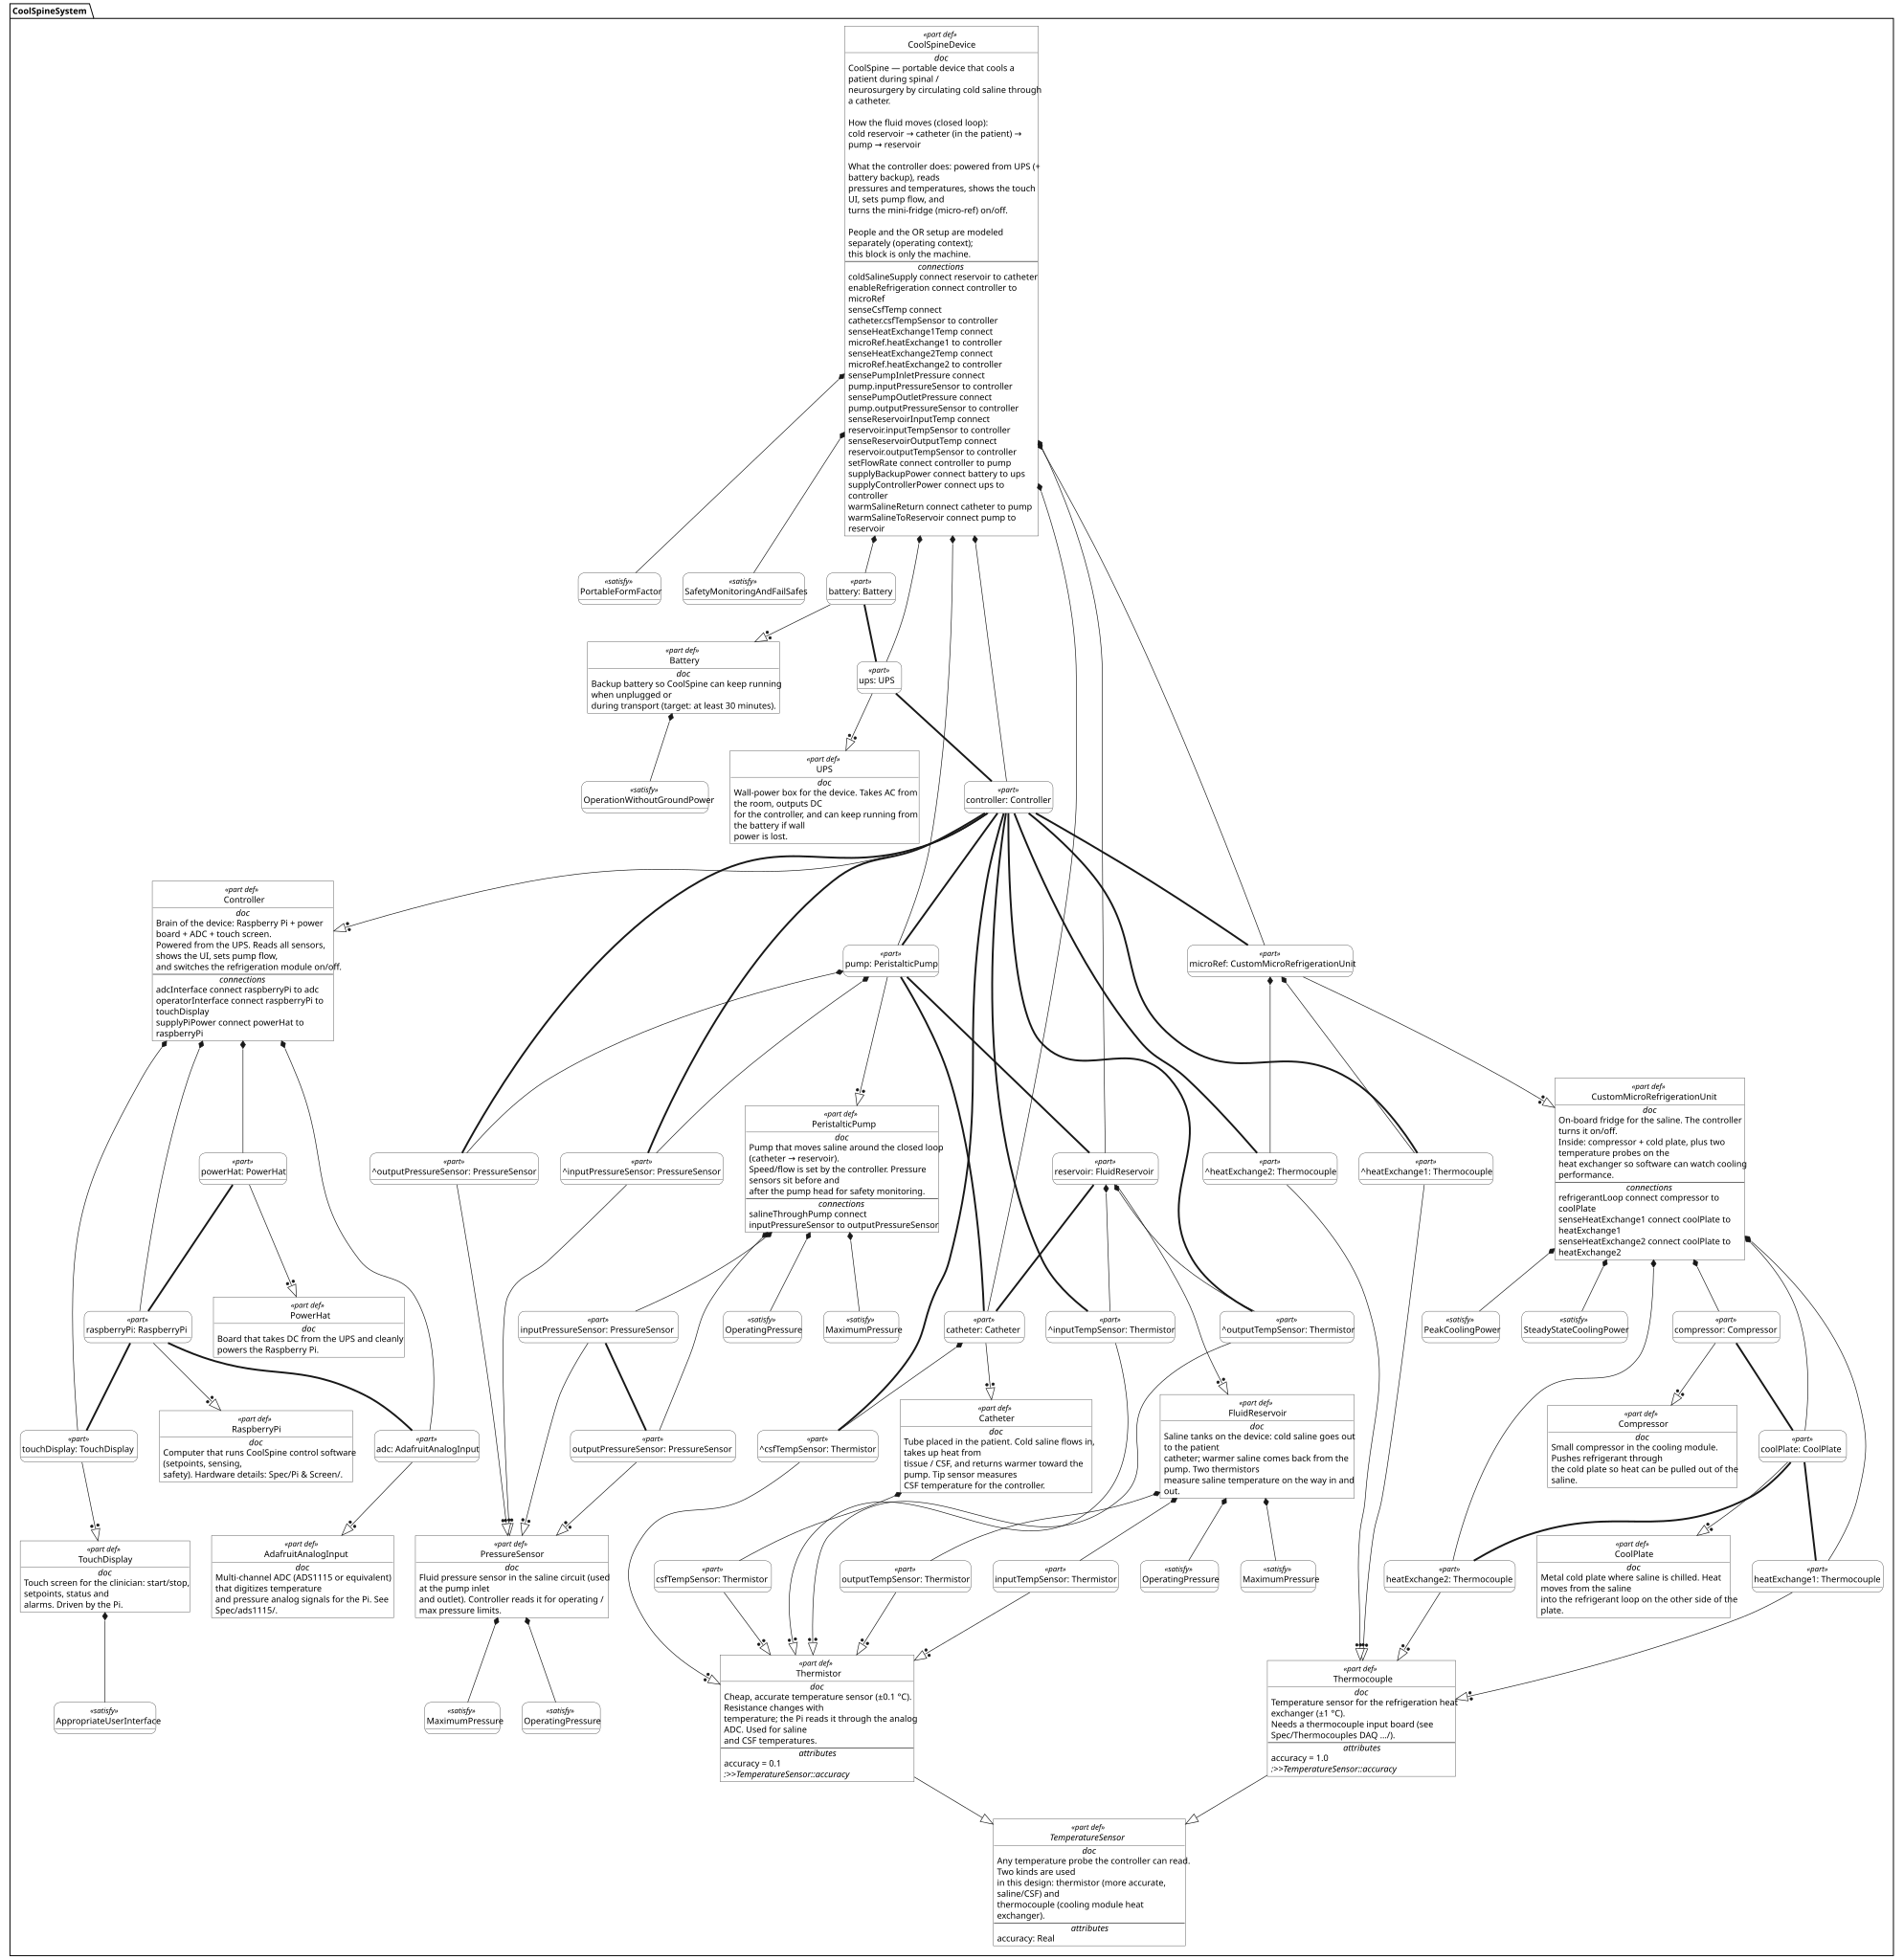

In [20]:
%viz CoolSpineSystem

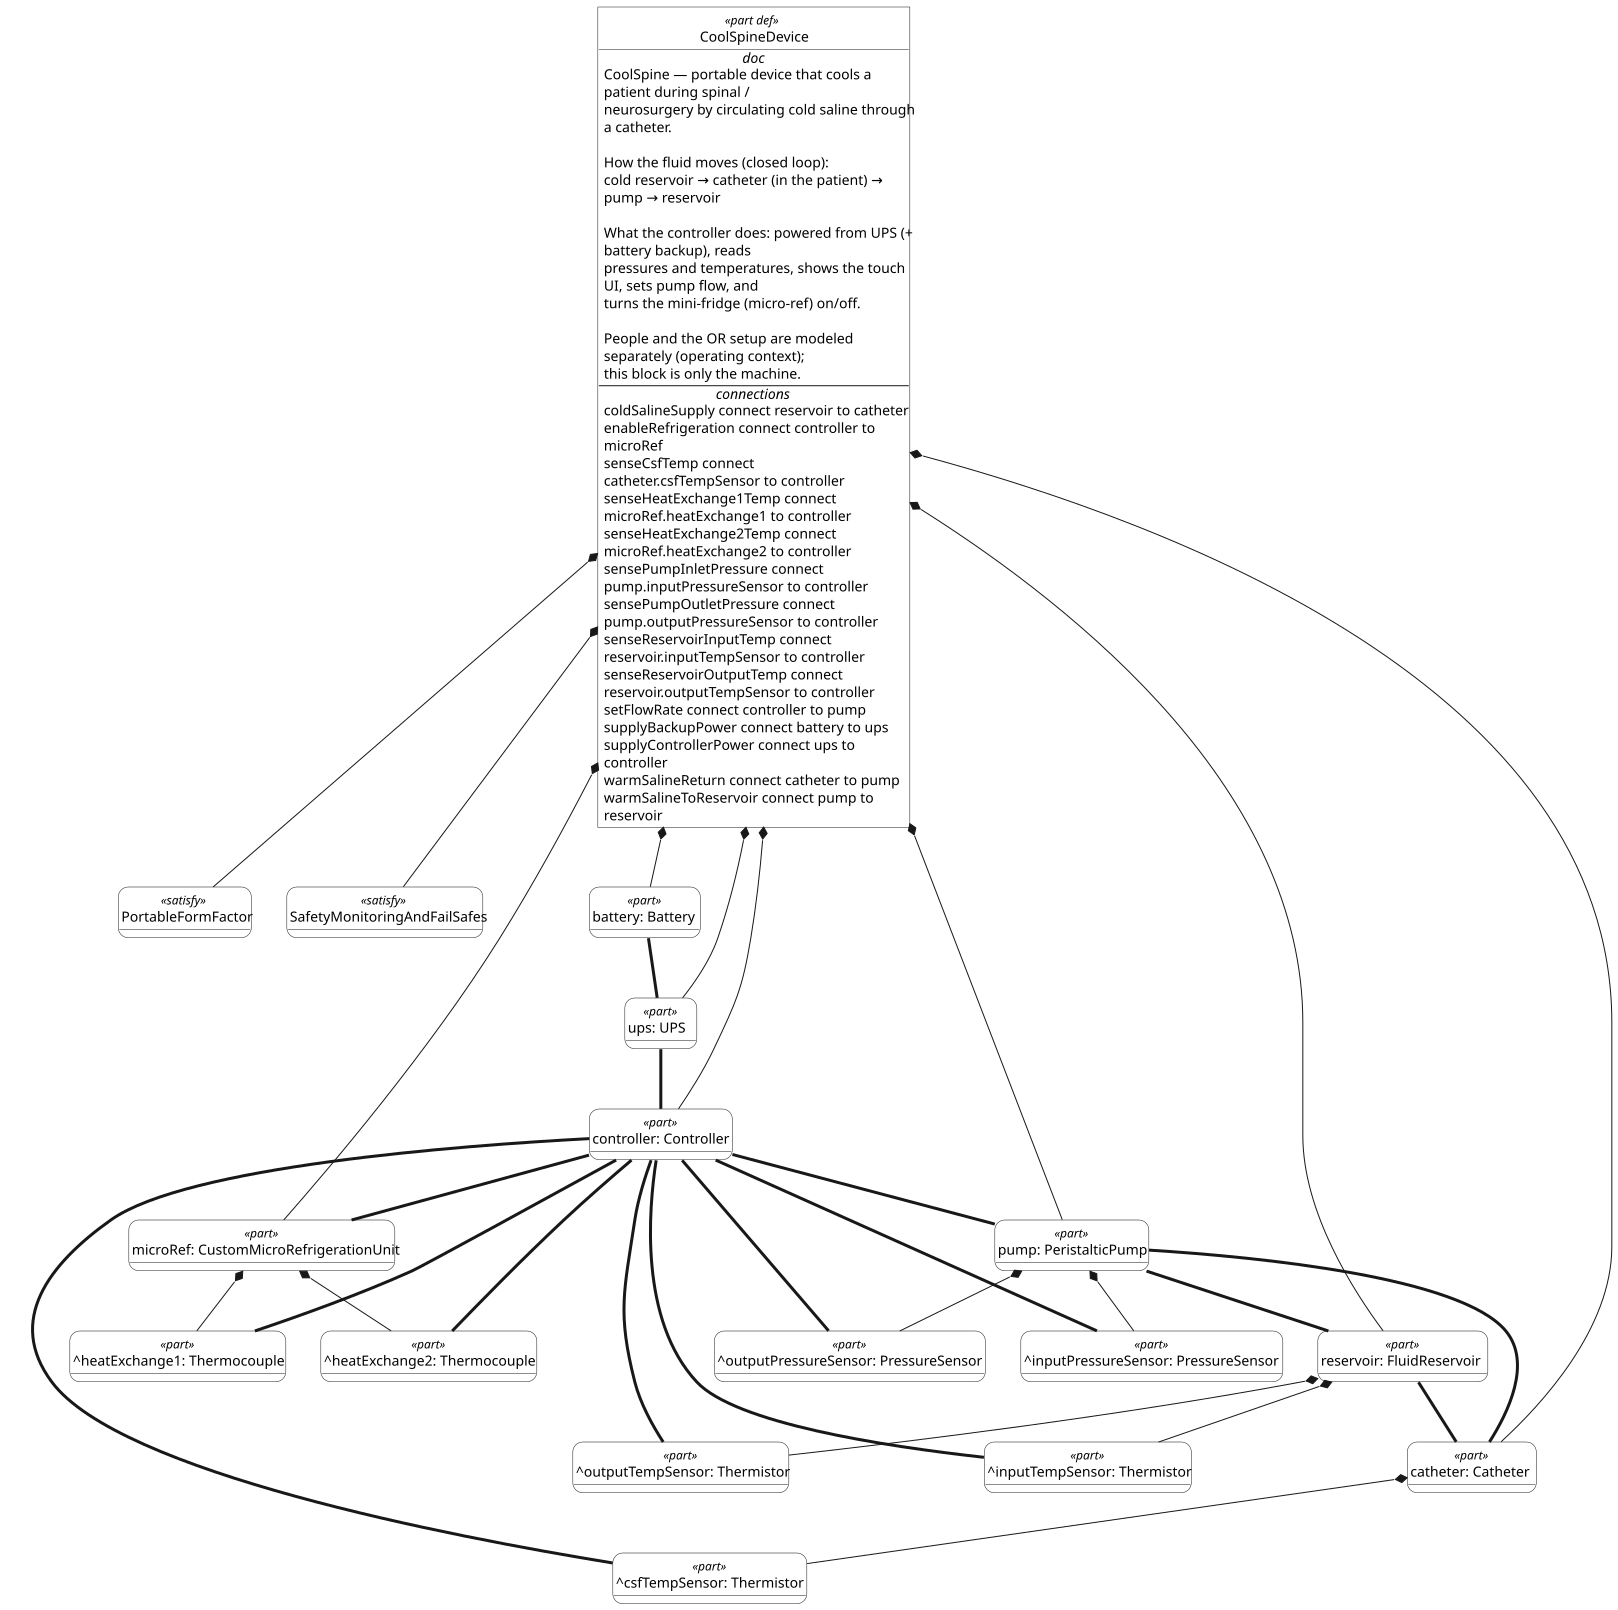

In [35]:
%viz --view TREE CoolSpineSystem::CoolSpineDevice

In [24]:
package CoolSpineUseCases {

    // Clinical scenarios. People come from CoolSpineSystemContext; the machine
    // is CoolSpineDevice from CoolSpineSystem.
    private import CoolSpineRequirements::*;
    private import CoolSpineSystem::*;
    private import CoolSpineSystemContext::*;

    // ------------------------------------------------------------------
    // Use cases
    // ------------------------------------------------------------------

    use case def DeliverTherapeuticCooling {
        doc /*
        Main clinical scenario: during spinal / neurosurgery the surgeon
        decides whether to use CoolSpine. If yes, the anesthesiologist powers
        it on, setpoints are agreed and entered, and CoolSpine cools until
        someone stops it. The patient benefits from the heat exchange.
        */

        actor surgeon : Surgeon {
            perform deliverCooling.decideWhetherToUse;
            perform deliverCooling.decideSetpoint;
        }

        actor anesthesiologist : Anesthesiologist {
            perform deliverCooling.switchDeviceOn;
            perform deliverCooling.enterSetpoint;
        }

        subject coolSpine : CoolSpineDevice {
            perform deliverCooling.completeSelfCheck;
            perform deliverCooling.startCoolingAndAwaitStop;
        }

        actor patient : Patient;

        objective {
            doc /*
            Keep commanded flow and cooling within safe pressure limits for
            as long as therapy is requested.
            */
        }

        satisfy 'REQ-CP-001';  // PeakCoolingPower
        satisfy 'REQ-CP-002';  // SteadyStateCoolingPower
        satisfy 'REQ-CP-005';  // OperatingPressure
        satisfy 'REQ-CP-006';  // MaximumPressure
        satisfy 'REQ-CP-007';  // AppropriateUserInterface
        satisfy 'REQ-CP-008';  // SafetyMonitoringAndFailSafes

        perform action deliverCooling {
            doc /*
            Happy path: decide to use → power on → self-check → setpoints →
            cool until stop. If the surgeon decides not to use CoolSpine,
            the flow ends immediately.
            */

            action decideWhetherToUse {
                doc /*
                Surgeon decides if CoolSpine will be used for this case.
                */
            }

            action switchDeviceOn {
                doc /* Anesthesiologist powers CoolSpine on. */
            }
            then completeSelfCheck;

            action completeSelfCheck {
                doc /*
                Device runs power-on checks; therapy continues only if OK.
                */
            }
            then decideSetpoint;

            action decideSetpoint {
                doc /* Surgeon picks the flow / temperature target. */
            }
            then enterSetpoint;

            action enterSetpoint {
                doc /* Anesthesiologist enters that target on the device UI. */
            }
            then startCoolingAndAwaitStop;

            action startCoolingAndAwaitStop {
                doc /*
                After setpoints are set, CoolSpine starts cooling and waits
                for a stop command.
                */
            }
            then done;

            first start;
            then decideWhetherToUse;
            then decide;
              if yes then switchDeviceOn;
              else done;
        }
    }

    use case def OperateWithoutGroundPower {
        doc /*
        Keep therapy going when there is no wall power — moving between rooms
        or a short AC outage. UPS + battery must cover at least the required
        hold-up time while safety monitoring stays active.
        */

        subject coolSpine : CoolSpineDevice;

        actor anesthesiologist : Anesthesiologist;

        objective {
            doc /*
            Therapy continues without wall power for at least 30 minutes, with
            safety monitoring and fail-safes still working.
            */
        }

        satisfy 'REQ-CP-003';  // OperationWithoutGroundPower
        satisfy 'REQ-CP-004';  // PortableFormFactor
        satisfy 'REQ-CP-008';  // SafetyMonitoringAndFailSafes
    }
}


ERROR:Couldn't resolve reference to Element 'yes'. (19.sysml line : 98 column : 18)
ERROR:Subject must be first parameter. (19.sysml line : 31 column : 9)


In [25]:
%viz CoolSpineUseCases

ERROR:Couldn't resolve reference to Element 'CoolSpineUseCases'


In [34]:
%viz -h

Usage: %viz [--view=<VIEW>] [--style=<STYLE>...] <NAME> [<NAME>...]

Visualize model elements of <NAME>(s). <NAME>s must be fully qualified.

<VIEW> is case insensitive and possible candidates are:
   DEFAULT		Automatically choose an appropriate view from the given model element names
   TREE			Show a tree-structural view, like a Block Definition Diagram (BDD)
   INTERCONNECTION	Show an interconnection view, like an Internal Block Diagram (IBD)
   STATE		Show state machines
   ACTION		Show actions like an activity diagram
   SEQUENCE		Show events and messages in a sequence diagram
   MIXED		Show multiple views

<STYLE> is also case insensitive. Multiple --style options are allowed.  The possible style names are:
  DEFAULT		Standard B&&W
  STDCOLOR		Standard style with colors
  PLANTUML		PlantUML Style
  TB			Top-to-Bottom orientation
  LR			Left-to-Right orientation
  POLYLINE		Polyline style
  ORTHOLINE		Orthogonal line style
  SHOWLIB		Show elements of the standard libraries
  SHOWIN